<a href="https://colab.research.google.com/github/sytluc0803/MSSP607/blob/main/Modules/Week_11/Week_11_Ex.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import userdata
import os

github_token = userdata.get('Git_Key')
owner = 'sytluc0803'
repository = 'MSSP607'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
import subprocess
subprocess.run(['git', 'clone', clone_url])

# Navigate into the cloned repository directory (optional, but often useful)
os.chdir(repository)
print(f"Changed directory to: {os.getcwd()}")

Changed directory to: /content/MSSP607


In [2]:
%pushd "/content/MSSP607/Modules/Week_11"

/content/MSSP607/Modules/Week_11


['/content/MSSP607']

In [6]:

!pip install geojson
!pip install geodatasets

#Import libraries and find some data
import pandas as pd
import geojson as gpd
import geopandas as gp
import matplotlib.pyplot as plt
import mapclassify
import geopandas
import geodatasets
from geodatasets import get_path

In [8]:
df = gp.read_file("california-congressional-districts.geojson")

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

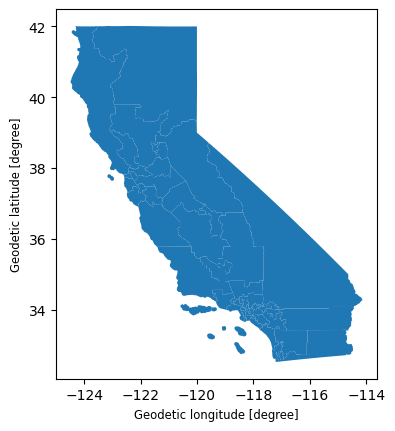

In [9]:
df.plot()

In [11]:
pf = pd.read_csv('CA_Legislative_Districts.csv')
pf['DISTRICT_N'] = pf['DISTRICT_N'].astype("float64")

In [13]:
pf['DISTRICT_N'].describe()

,DISTRICT_N
count,52.000000
mean,26.500000
std,15.154757
min,1.000000
25%,13.750000
50%,26.500000
75%,39.250000
max,52.000000


In [15]:
pf.head()

,OBJECTID,ID,AREA,DISTRICT,MEMBERS,NAME,POPULATION,CVAP_19,HSP_CVAP_1,DOJ_NH_BLK,...,MULTIPLE_F,F_CVAP_19,F_HSP_CVAP,F_DOJ_NH_B,F_DOJ_NH_A,F_NH_WHT_C,DISTRICT_L,DISTRICT_N,SHAPE_Length,SHAPE_Area
0,1,1,27014.63,1,1,MTCAP,760066,549203,77031,10923,...,1|0,0.7226,0.1403,0.0199,0.0475,0.7507,1|0%,1.0,2.633906e+06,1.222952e+11
1,2,2,560.65,10,1,STANI,760066,503249,67160,26317,...,10|0,0.6621,0.1335,0.0523,0.1713,0.6220,10|0%,10.0,3.582890e+05,2.336909e+09
2,3,3,226.43,11,1,COCO,760067,568460,61171,33907,...,11|1,0.7479,0.1076,0.0596,0.3160,0.5006,11|0%,11.0,2.111932e+05,9.404054e+08
3,4,4,141.25,12,1,SF,760065,510978,74038,101894,...,12|-1,0.6723,0.1449,0.1994,0.2139,0.4169,12|-0%,12.0,1.246786e+05,5.869476e+08
4,5,5,6346.92,13,1,OKLND,760065,393416,197645,16042,...,13|-1,0.5176,0.5024,0.0408,0.0621,0.3708,13|-0%,13.0,1.186868e+06,2.578115e+10


In [17]:
df['Name'] = df['Name'].astype("int")
districts = df.merge(pf, how = 'left', left_on = "Name", right_on = "DISTRICT_N")

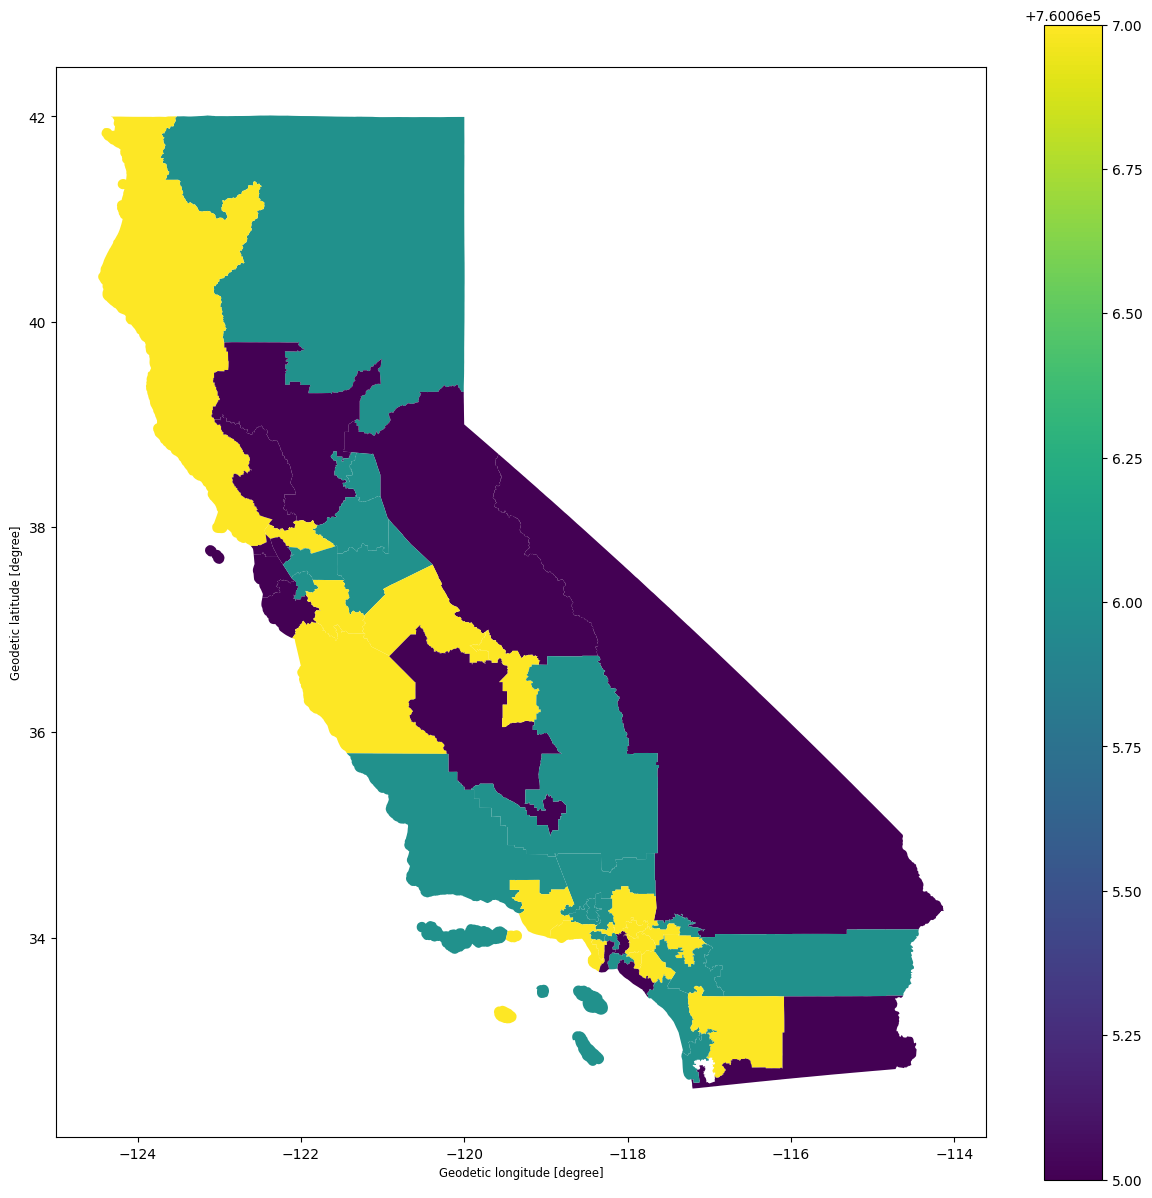

In [18]:
fig, ax2 = plt.subplots(figsize = (15,15))
districts.plot('POPULATION', figsize = (15,15), legend = True, ax = ax2)
fig.show()